# MFPCA vs. FPCA clàssica (domini comú) — versió simplificada

Autor: Leonel Fernando Nabaza Ruibal

Versió simplificada de la comprovació MFPCA (Happ & Greven, 2018) ↔ FPCA clàssica
quan el domini és el mateix per a totes les variables, amb funcions senzilles
(sinus i cosinus) en lloc d'una base de Fourier general.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from FDApy.representation.functional_data import DenseFunctionalData, MultivariateFunctionalData
from FDApy.representation.argvals import DenseArgvals
from FDApy.representation.values import DenseValues
from FDApy.preprocessing.dim_reduction.mfpca import MFPCA
from FDApy.preprocessing.dim_reduction.ufpca import UFPCA

np.random.seed(123)


---
# Part 1 — Funcions i generació de les dades

Generem $n$ individus amb dues variables funcionals $X^{(1)}(t), X^{(2)}(t)$ sobre el
mateix domini $t\in[0,2\pi]$:

$$
X^{(1)}(t) = \xi_1 \sin(t) + \xi_2 \cos(2t) + \varepsilon^{(1)}(t)
$$
$$
X^{(2)}(t) = \xi_1 \cos(t) + \xi_2 \sin(2t) + \varepsilon^{(2)}(t)
$$

on:

- $\xi_1 \sim N(0,4)$, $\xi_2 \sim N(0,1)$ són els **mateixos** dos "scores" per a
  cada individu (això és el que correlaciona $X^{(1)}$ i $X^{(2)}$),
- $X^{(1)}$ i $X^{(2)}$ combinen aquests mateixos scores amb funcions sinus/cosinus
  diferents,
- $\varepsilon^{(j)}(t)$ és soroll blanc gaussià petit.

Com que el model generador només té 2 fonts de variació ($\xi_1,\xi_2$), esperem
recuperar **2 components principals**.


In [2]:
n = 150
t = np.linspace(0, 2*np.pi, 100)
argvals = DenseArgvals({'input_dim_0': t})

xi1 = np.random.normal(scale=2.0, size=n)   # sd = sqrt(4)
xi2 = np.random.normal(scale=1.0, size=n)   # sd = sqrt(1)

X1 = np.outer(xi1, np.sin(t)) + np.outer(xi2, np.cos(2*t)) + 0.1*np.random.randn(n, len(t))
X2 = np.outer(xi1, np.cos(t)) + np.outer(xi2, np.sin(2*t)) + 0.1*np.random.randn(n, len(t))


## Construcció dels objectes funcionals

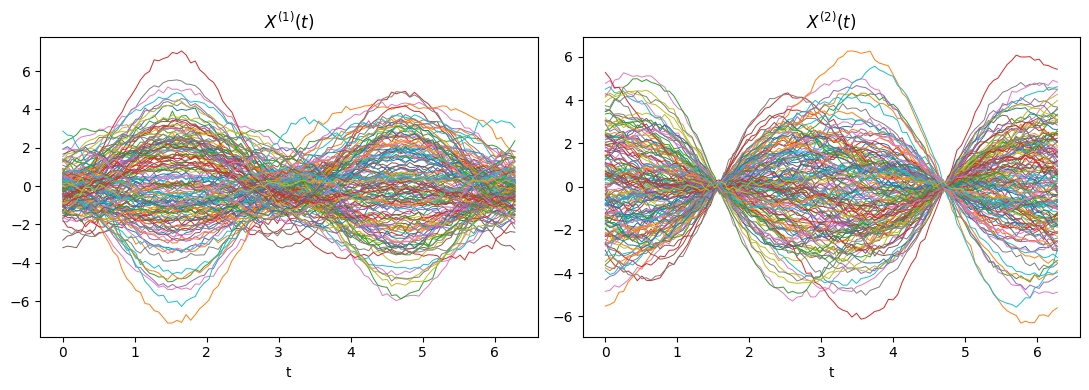

In [3]:
fd1 = DenseFunctionalData(argvals, DenseValues(X1))
fd2 = DenseFunctionalData(argvals, DenseValues(X2))
mData = MultivariateFunctionalData([fd1, fd2])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, X1.T, linewidth=0.7)
axes[0].set_title("$X^{(1)}(t)$")
axes[0].set_xlabel("t")
axes[1].plot(t, X2.T, linewidth=0.7)
axes[1].set_title("$X^{(2)}(t)$")
axes[1].set_xlabel("t")
plt.tight_layout()
plt.show()


---
# Part 2 — (A) MFPCA de Happ & Greven


In [4]:
K = 2  # el model generador té 2 components

uniExpansions = [
    {'method': 'UFPCA', 'n_components': 8},
    {'method': 'UFPCA', 'n_components': 8},
]

mfpca = MFPCA(n_components=K, method='covariance', univariate_expansions=uniExpansions)
mfpca.fit(mData)
scores_mfpca = mfpca.transform(mData)

print("Valors propis (MFPCA):", np.round(mfpca.eigenvalues, 4))


Valors propis (MFPCA): [30.0737  5.7084]


---
# Part 3 — (B) FPCA clàssica via concatenació

Ajuntem $X^{(1)}$ i $X^{(2)}$ en una sola corba $Z(t)$, definida sobre un domini
doble $[0,4\pi]$ ($X^{(1)}$ a la primera meitat, $X^{(2)}$ a la segona), i li
apliquem una FPCA univariant estàndard (`UFPCA`).


In [5]:
delta = t[1] - t[0]
t_concat = np.concatenate([t, t + t[-1] + delta])
argvals_concat = DenseArgvals({'input_dim_0': t_concat})
X_concat = np.concatenate([X1, X2], axis=1)

fd_concat = DenseFunctionalData(argvals_concat, DenseValues(X_concat))

ufpca = UFPCA(n_components=K, method='covariance')
ufpca.fit(fd_concat)
scores_ufpca = ufpca.transform(fd_concat)

print("Valors propis (FPCA clàssica):", np.round(ufpca.eigenvalues, 4))


Valors propis (FPCA clàssica): [30.2323  5.7442]


---
# Part 4 — Comparació de resultats


In [6]:
print("Valors propis MFPCA        :", np.round(mfpca.eigenvalues, 4))
print("Valors propis FPCA clàssica :", np.round(ufpca.eigenvalues, 4))
print("Diferència relativa         :",
      np.round(np.abs(mfpca.eigenvalues - ufpca.eigenvalues) / ufpca.eigenvalues, 4))

print("\nCorrelació entre scores (ha de ser ≈ ±1):")
for k in range(K):
    corr = np.corrcoef(scores_mfpca[:, k], scores_ufpca[:, k])[0, 1]
    print(f"  Component {k+1}: {corr:.4f}")


Valors propis MFPCA        : [30.0737  5.7084]
Valors propis FPCA clàssica : [30.2323  5.7442]
Diferència relativa         : [0.0052 0.0062]

Correlació entre scores (ha de ser ≈ ±1):
  Component 1: -1.0000
  Component 2: 1.0000


## Comparació visual de la 1a autofunció

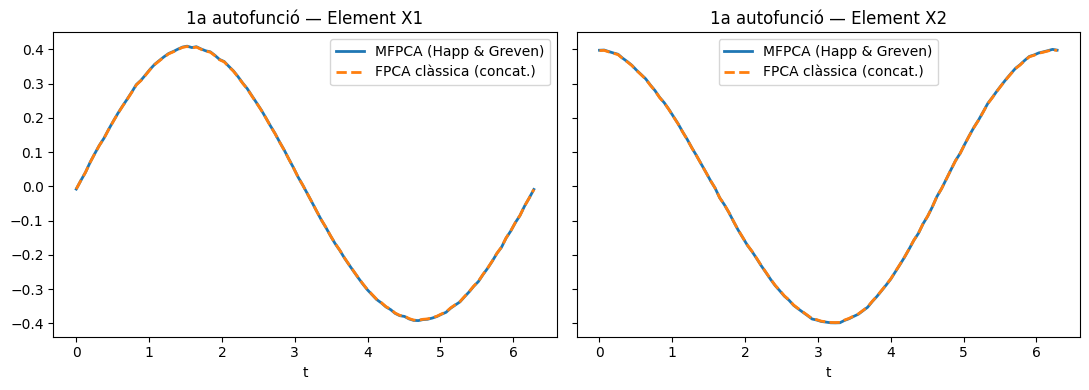

In [7]:
ef_mfpca_X1 = mfpca.eigenfunctions.data[0].to_grid()
ef_mfpca_X2 = mfpca.eigenfunctions.data[1].to_grid()
ef_ufpca    = ufpca.eigenfunctions   # ja en graella

n_t = len(t)
ef_classic_X1 = ef_ufpca.values[:, :n_t]
ef_classic_X2 = ef_ufpca.values[:, n_t:]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ef_m, ef_c, titol in zip(
    axes,
    [ef_mfpca_X1.values, ef_mfpca_X2.values],
    [ef_classic_X1, ef_classic_X2],
    ["Element X1", "Element X2"],
):
    signe = np.sign(np.corrcoef(ef_m[0], ef_c[0])[0, 1])
    ax.plot(t, ef_m[0], label="MFPCA (Happ & Greven)", lw=2)
    ax.plot(t, signe * ef_c[0], "--", label="FPCA clàssica (concat.)", lw=2)
    ax.set_title(f"1a autofunció — {titol}")
    ax.set_xlabel("t")
    ax.legend()

plt.tight_layout()
plt.show()


---
# Conclusió

Amb funcions més senzilles (sinus i cosinus) el resultat és el mateix: quan el
domini és comú, la MFPCA i la FPCA clàssica donen valors propis pràcticament
idèntics, scores perfectament correlacionats (llevat de signe) i les mateixes
autofuncions partides pels dos elements.
